Tabela 2 -- Redes criadas com Havel–Hakimi
Rede                   m   media      var     d_A       L  isol  comp  maior
Anel com atalhos     900   6.000    0.567   6.094   6.009     0     1    300
Sorteio de pares     938   6.253    5.656   7.158   6.305     1    11    266
Com populares        891   5.940   32.783  11.459   7.088     0    33    172

Tabela 3 -- Grau inicial e alcance médio (%)
Rede                 grau dir  grau ind   alc dir   alc ind
Anel com atalhos         6.00      6.01     14.15     14.20
Sorteio de pares         6.30      6.30     16.26     16.12
Com populares            5.94      6.96     20.11     20.54
Imagem salva: ../relatorio/grafo_anel.png


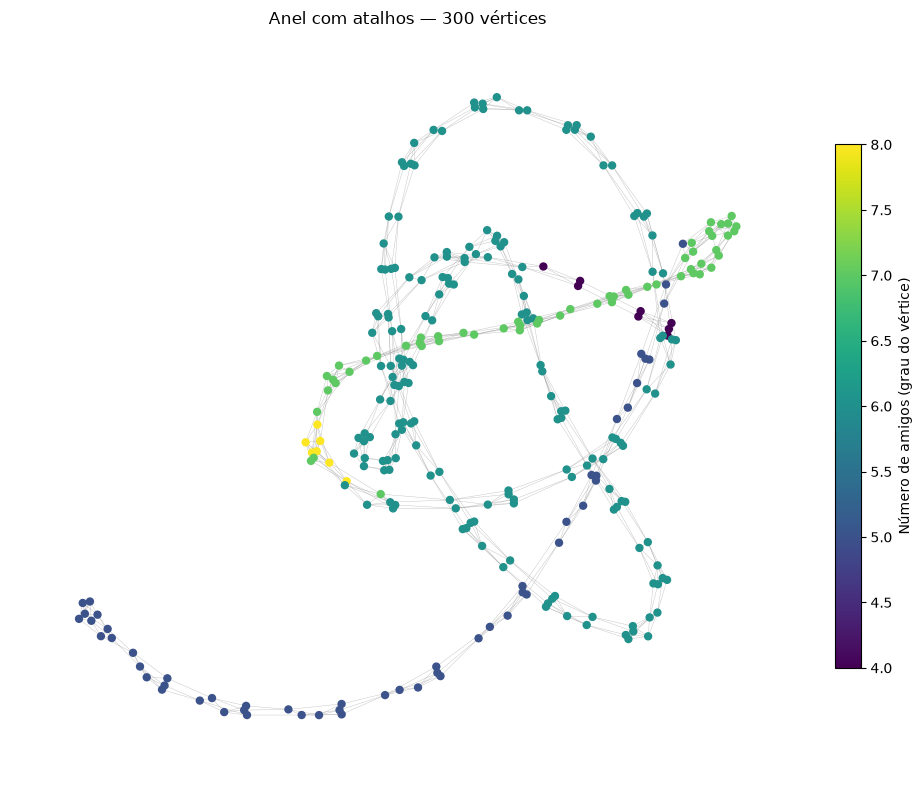

Imagem salva: ../relatorio/grafo_pares.png


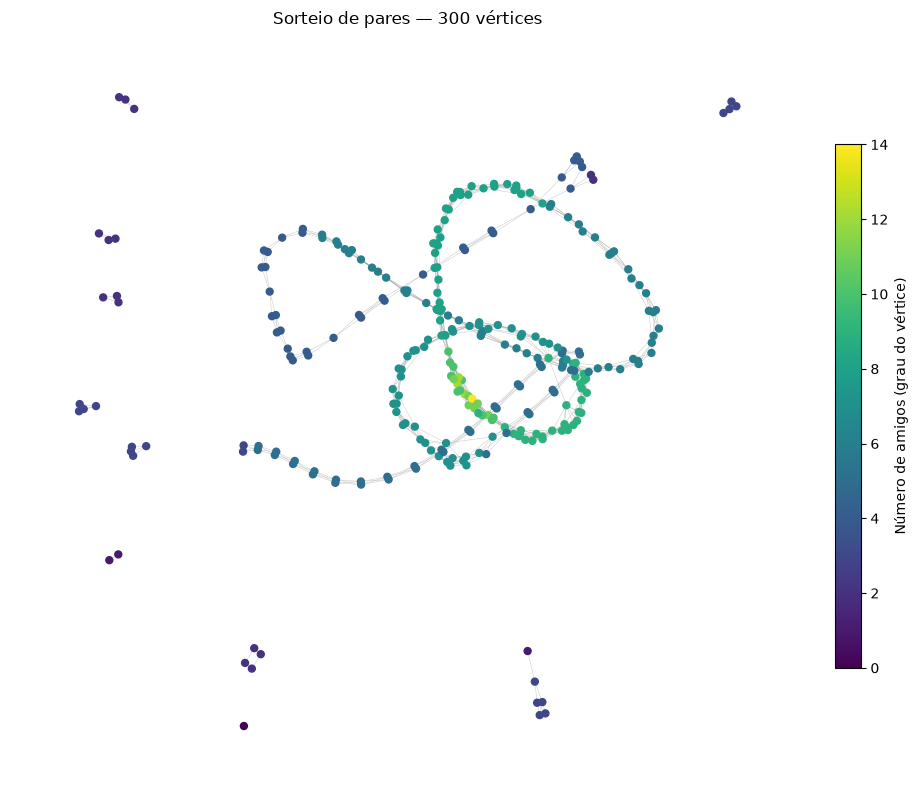

Imagem salva: ../relatorio/grafo_populares.png


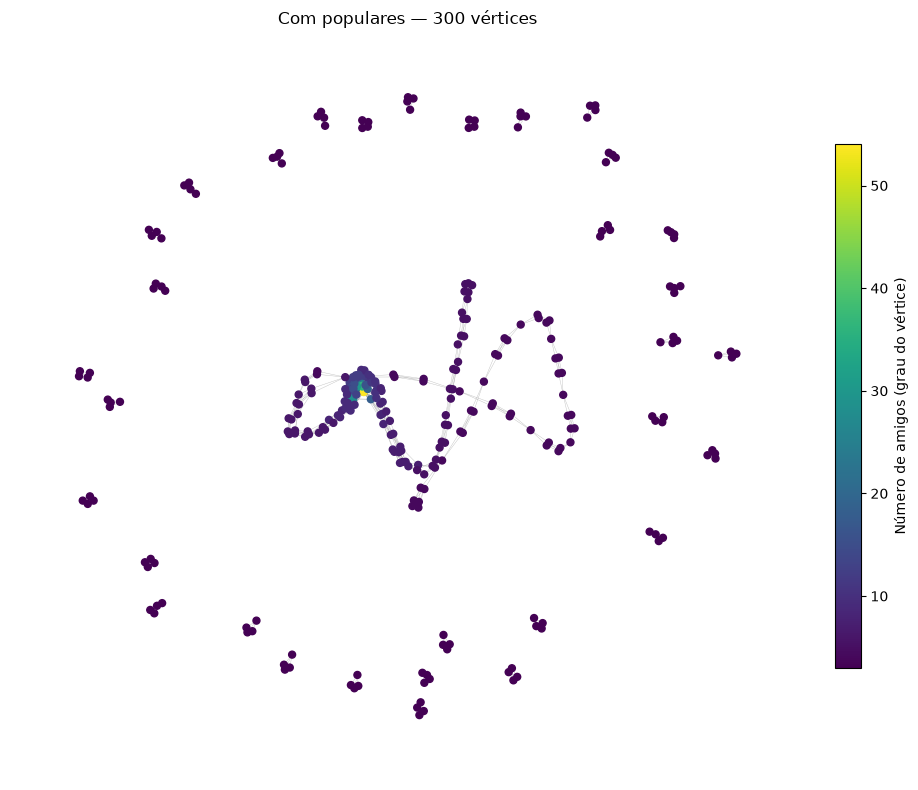

In [2]:

"""
Paradoxo da Amizade — redes construídas com Havel–Hakimi.

Como rodar:
    python -m pip install networkx matplotlib
    python simulacao_paradoxo_amizade.py

Primeiro criamos SEQUÊNCIAS DE GRAUS (sem criar grafos).
Depois verificamos e construímos os grafos com Havel–Hakimi.
Por fim, calculamos médias, simulamos a divulgação de uma notícia
e visualizamos os três grafos.

Observação: as sequências imitam padrões de graus dos modelos
Watts–Strogatz, Erdős–Rényi e Barabási–Albert, mas as CONEXÕES finais
são sempre determinadas por Havel–Hakimi. Portanto, não são realizações
exatas desses três modelos de redes.
"""

import random
import networkx as nx
import matplotlib.pyplot as plt

SEMENTE = 42
N = 300
K_INICIAIS = 15
RODADAS = 4
P_TRANSMITIR = 0.15
REPETICOES = 500


# ---------------------------------------------------------------
# 1. Criar apenas as sequências de graus (ainda sem grafos)
# ---------------------------------------------------------------
def graus_anel_com_atalhos(rng):
    """Graus aproximadamente como os de um anel com 10% de reconexões."""
    graus = [6] * N  # cada pessoa começa com 6 amigos

    # Cada vértice tem 3 arestas 'para a frente' no anel original.
    # Aproximamos o efeito das reconexões SOMENTE sobre os graus.
    for u in range(N):
        for distancia in range(1, 4):
            if rng.random() < 0.1:
                antigo_vizinho = (u + distancia) % N
                novo_vizinho = rng.randrange(N)
                while novo_vizinho in (u, antigo_vizinho):
                    novo_vizinho = rng.randrange(N)
                graus[antigo_vizinho] -= 1
                graus[novo_vizinho] += 1
    return graus


def graus_sorteio_de_pares(rng):
    """Graus com distribuição binomial aproximando Erdős–Rényi."""
    p = 6 / (N - 1)
    return [sum(rng.random() < p for _ in range(N - 1)) for _ in range(N)]


def graus_com_populares(rng):
    """Crescimento por preferência de grau, sem armazenar arestas.

    Começamos com os graus de uma estrela de 4 vértices. Cada nova pessoa
    escolhe 3 pessoas distintas, com probabilidade proporcional ao grau.
    Assim obtemos apenas a sequência de graus, antes de construir o grafo.
    """
    graus = [3, 1, 1, 1]
    while len(graus) < N:
        candidatos = list(range(len(graus)))
        escolhidos = []
        for _ in range(3):
            pesos = [graus[u] for u in candidatos]
            u = rng.choices(candidatos, weights=pesos, k=1)[0]
            escolhidos.append(u)
            candidatos.remove(u)  # não escolher a mesma pessoa duas vezes
        for u in escolhidos:
            graus[u] += 1
        graus.append(3)  # a nova pessoa criou 3 amizades
    return graus


def gerar_redes():
    rng = random.Random(SEMENTE)
    geradores = {
        "Anel com atalhos": graus_anel_com_atalhos,
        "Sorteio de pares": graus_sorteio_de_pares,
        "Com populares": graus_com_populares,
    }
    redes = {}

    for nome, gerar_graus in geradores.items():
        # Repete se uma sequência aleatória não puder formar um grafo simples.
        for tentativa in range(100):
            graus = gerar_graus(rng)
            if nx.is_graphical(graus, method="hh"):
                break
        else:
            raise RuntimeError(f"Não foi possível gerar sequência gráfica: {nome}")

        # AQUI o grafo é construído pela primeira vez: Havel–Hakimi!
        G = nx.havel_hakimi_graph(graus)

        # Confere que a sequência de graus foi preservada.
        # A numeração dos vértices pode mudar, especialmente com isolados.
        assert sorted(d for _, d in G.degree()) == sorted(graus)
        redes[nome] = G

    return redes


# ---------------------------------------------------------------
# 2. Médias e conectividade
# ---------------------------------------------------------------
def medias(G):
    graus = [d for _, d in G.degree()]
    n = len(graus)
    m = G.number_of_edges()
    soma = sum(graus)                # = 2m (lema do aperto de mãos)
    soma_quadrados = sum(d * d for d in graus)

    media = soma / n
    variancia = soma_quadrados / n - media ** 2
    media_amigos = soma_quadrados / soma if soma else 0.0

    com_amigos = [u for u in G if G.degree(u) > 0]
    L = (
        sum(sum(G.degree(v) for v in G[u]) / G.degree(u)
            for u in com_amigos) / len(com_amigos)
        if com_amigos else 0.0
    )
    isolados = n - len(com_amigos)
    componentes = list(nx.connected_components(G))
    quantidade_componentes = len(componentes)
    maior_componente = max(map(len, componentes), default=0)

    return (m, media, variancia, media_amigos, L,
            isolados, quantidade_componentes, maior_componente)


# ---------------------------------------------------------------
# 3. Escolha das pessoas e espalhamento da notícia
# ---------------------------------------------------------------
def escolher_direto(G, rng):
    """Escolhe 15 pessoas uniformemente, sem repetição."""
    return rng.sample(list(G.nodes()), K_INICIAIS)


def escolher_por_indicacao(G, rng):
    """Sorteia uma pessoa com amigos; depois, um de seus amigos."""
    com_amigos = [u for u in G if G.degree(u) > 0]
    possiveis_indicados = {v for u in com_amigos for v in G[u]}
    if len(possiveis_indicados) < K_INICIAIS:
        raise ValueError("Não existem 15 pessoas diferentes para indicar.")

    escolhidos = set()
    while len(escolhidos) < K_INICIAIS:
        pessoa = rng.choice(com_amigos)
        amigo = rng.choice(list(G[pessoa]))
        escolhidos.add(amigo)
    return list(escolhidos)


def espalhar(G, iniciais, rng):
    """Em 4 rodadas, só os novos informados tentam avisar seus amigos."""
    sabem = set(iniciais)
    novos = set(iniciais)
    for _ in range(RODADAS):
        proximos = set()
        for u in novos:
            for v in G[u]:
                if v not in sabem and rng.random() < P_TRANSMITIR:
                    proximos.add(v)
        sabem |= proximos
        novos = proximos
    return len(sabem)


def experimento(G, escolher, rng):
    soma_grau = 0.0
    soma_alcance = 0.0
    for _ in range(REPETICOES):
        iniciais = escolher(G, rng)
        soma_grau += sum(G.degree(u) for u in iniciais) / len(iniciais)
        soma_alcance += 100 * espalhar(G, iniciais, rng) / len(G)
    return soma_grau / REPETICOES, soma_alcance / REPETICOES


# ---------------------------------------------------------------
# 4. Visualização dos grafos
# ---------------------------------------------------------------


def visualizar_grafo(G, titulo, arquivo):
    """Desenha o grafo com legenda de cores e salva em PNG."""

    fig, ax = plt.subplots(figsize=(10, 8))

    pos = nx.spring_layout(G, seed=SEMENTE)
    graus = [G.degree(u) for u in G.nodes()]

    # Desenha as arestas
    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edge_color="gray",
        width=0.3,
        alpha=0.5
    )

    # Desenha os vértices com cores conforme seus graus
    vertices = nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_size=25,
        node_color=graus,
        cmap=plt.cm.viridis,
        vmin=min(graus),
        vmax=max(graus)
    )

    # Adiciona a barra de cores
    barra = fig.colorbar(vertices, ax=ax, shrink=0.7, pad=0.03)
    barra.set_label("Número de amigos (grau do vértice)")

    ax.set_title(f"{titulo} — {G.number_of_nodes()} vértices")
    ax.axis("off")

    fig.tight_layout()
    fig.savefig(arquivo, dpi=200, bbox_inches="tight")

    print(f"Imagem salva: {arquivo}")

    plt.show()
    plt.close(fig)



# ---------------------------------------------------------------
# 5. Programa principal
# ---------------------------------------------------------------
def main():
    redes = gerar_redes()

    print("Tabela 2 -- Redes criadas com Havel–Hakimi")
    print(f"{'Rede':<19}{'m':>5}{'media':>8}{'var':>9}{'d_A':>8}{'L':>8}"
          f"{'isol':>6}{'comp':>6}{'maior':>7}")
    for nome, G in redes.items():
        m, media, var, dA, L, iso, comp, maior = medias(G)
        print(f"{nome:<19}{m:>5}{media:>8.3f}{var:>9.3f}"
              f"{dA:>8.3f}{L:>8.3f}{iso:>6}{comp:>6}{maior:>7}")

    print("\nTabela 3 -- Grau inicial e alcance médio (%)")
    print(f"{'Rede':<19}{'grau dir':>10}{'grau ind':>10}{'alc dir':>10}{'alc ind':>10}")
    rng = random.Random(SEMENTE)
    for nome, G in redes.items():
        g_dir, a_dir = experimento(G, escolher_direto, rng)
        g_ind, a_ind = experimento(G, escolher_por_indicacao, rng)
        print(f"{nome:<19}{g_dir:>10.2f}{g_ind:>10.2f}"
              f"{a_dir:>10.2f}{a_ind:>10.2f}")

    # Os desenhos são gerados no final, sem interferir nos cálculos acima.
    arquivos = {
    "Anel com atalhos": "../relatorio/grafo_anel.png",
    "Sorteio de pares": "../relatorio/grafo_pares.png",
    "Com populares": "../relatorio/grafo_populares.png",
}
    for nome, G in redes.items():
        visualizar_grafo(G, nome, arquivos[nome])


if __name__ == "__main__":
    main()
